REFERENCE VALUES
Rh1: 3.48
Area: 0.8861
R2: 0.99951
viscosity_Pa_s: 0.00089
capillary_diameter_um: 75.0
temperature_C: 25.0

MEASUREMENT LOADED
Measurements: 2162
First x: 0.000000
Last x: 3.001389

AUTOMATIC PEAK ANALYSIS
Peak maximum: 2.940278 min
Fitted center: 2.830380 min
Fitted Gaussian sigma: 7.924960 sec
Left boundary: 2.434722 min
Right boundary: 3.001389 min
Peak area: 0.002192
Standard sigma: 8.672617 sec

HYDRODYNAMIC RADIUS
Diffusion coefficient: 7.759025e-11 m²/s
Hydrodynamic radius Rh: 3.1624 nm

RESULT DESCRIPTION
The calculated hydrodynamic radius (Rh) of the sample is 3.1624 nm. The value was determined using Gaussian-guided weighted moment analysis (GGWMA), followed by the Stokes-Einstein equation.

REFERENCE COMPARISON
Calculated area: 0.002192
Reference area: 0.886100
Calculated Rh: 3.1624 nm
Reference Rh: 3.4800 nm
Rh difference: -0.3176 nm
Rh percentage difference: 9.13%


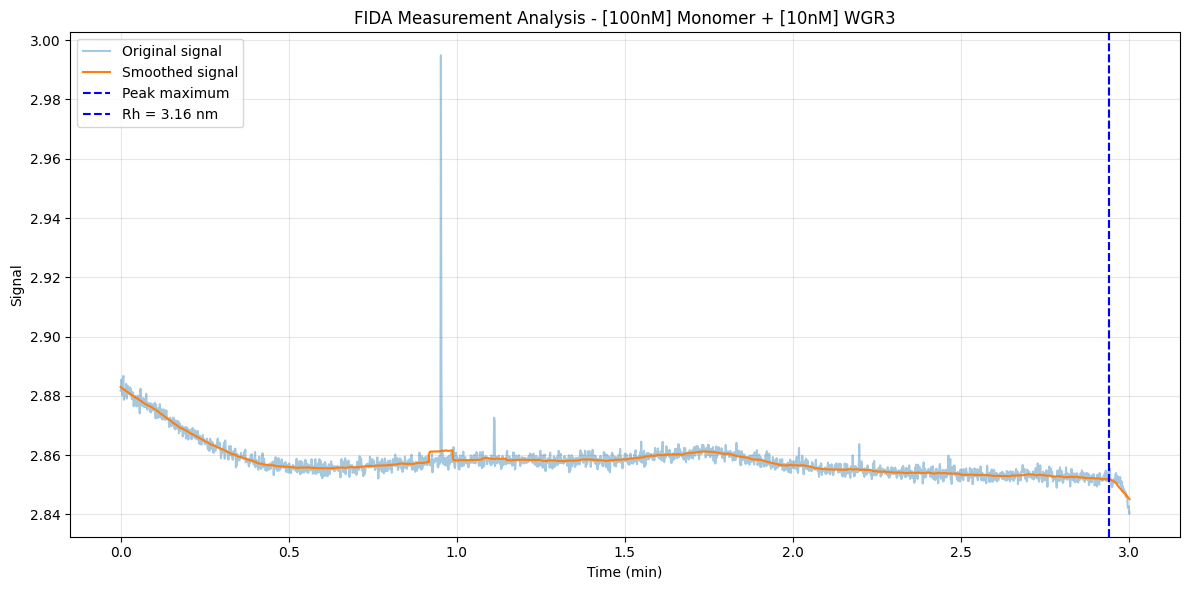

In [122]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit


# ==========================================
# 1. FIDA REFERENCE VALUES
# ==========================================

reference = {
    "Rh1": 3.48,
    "Area": 0.8861,
    "R2": 0.99951,
    "viscosity_Pa_s": 0.00089,
    "residence_time_min": 1.659988,
    "capillary_diameter_um": 75.0,
    "temperature_C": 25.0
}

print("REFERENCE VALUES")
print("================")

# Residence time is kept for calculations,
# but is not displayed here.
for parameter, value in reference.items():
    if parameter != "residence_time_min":
        print(f"{parameter}: {value}")


# ==========================================
# 2. LOAD CSV DATA
# ==========================================

# Replace this with your existing file path
file_name = r"C:\Users\1\Desktop\Bachelor\FIDA-DATA-CSV\Første dag\10nM WGR1.csv"

data = pd.read_csv(
    file_name,
    sep=";",
    header=None,
    usecols=[0, 1],
    names=["x", "signal"],
    dtype=str
)

for col in ["x", "signal"]:
    data[col] = (
        data[col]
        .str.strip()
        .str.replace(",", ".", regex=False)
    )
    data[col] = pd.to_numeric(data[col], errors="raise")

x = data["x"].to_numpy(dtype=float)
signal_original = data["signal"].to_numpy(dtype=float)

# Sort data before analysis
order = np.argsort(x)
x = x[order]
signal_original = signal_original[order]

assert len(x) == len(signal_original)
assert np.isfinite(x).all()
assert np.isfinite(signal_original).all()

print("\nMEASUREMENT LOADED")
print("==================")
print(f"Measurements: {len(x)}")
print(f"First x: {x[0]:.6f}")
print(f"Last x: {x[-1]:.6f}")


# ==========================================
# 3. SMOOTHING
# ==========================================

window_length = 51
polyorder = 1

signal_smooth = savgol_filter(
    signal_original,
    window_length=window_length,
    polyorder=polyorder
)


# ==========================================
# 4. BASELINE CORRECTION
# ==========================================

baseline = np.linspace(
    signal_smooth[0],
    signal_smooth[-1],
    len(signal_smooth)
)

corrected = signal_smooth - baseline
weights = np.maximum(corrected, 0)


# ==========================================
# 5. AUTOMATIC PEAK FIT
# ==========================================

# Find peak maximum
peak_index = np.argmax(weights)

peak_x = x[peak_index]
peak_height = weights[peak_index]

# Gaussian model with offset
def gaussian(x, amplitude, center, sigma, offset):
    return (
        amplitude
        * np.exp(-0.5 * ((x - center) / sigma)**2)
        + offset
    )

# Fit around the peak
fit_mask = (
    (x >= peak_x - 0.5)
    & (x <= peak_x + 0.5)
)

x_fit = x[fit_mask]
y_fit = weights[fit_mask]

initial_guess = [
    peak_height,
    peak_x,
    0.15,
    0.0
]

parameters, covariance = curve_fit(
    gaussian,
    x_fit,
    y_fit,
    p0=initial_guess,
    bounds=(
        [0, x_fit.min(), 0.001, -np.inf],
        [np.inf, x_fit.max(), 1.0, np.inf]
    ),
    maxfev=20000
)

amplitude_fit, center_fit, sigma_fit, offset_fit = parameters

# Use fitted Gaussian width to define the interval.
# Three fitted standard deviations on either side.
left_time = center_fit - 3 * sigma_fit
right_time = center_fit + 3 * sigma_fit

# Restrict interval to available data
left_index = np.argmin(np.abs(x - left_time))
right_index = np.argmin(np.abs(x - right_time))

if right_index <= left_index:
    raise ValueError("Invalid fitted peak interval.")

x_peak = x[left_index:right_index + 1]
weights_peak = weights[left_index:right_index + 1]


# ==========================================
# 6. STANDARD WEIGHTED SIGMA
# ==========================================

area = np.trapezoid(weights_peak, x_peak)

if area <= 0:
    raise ValueError("Peak area must be positive.")

mu = (
    np.trapezoid(x_peak * weights_peak, x_peak)
    / area
)

variance = (
    np.trapezoid(
        (x_peak - mu)**2 * weights_peak,
        x_peak
    ) / area
)

sigma_min = np.sqrt(variance)
sigma_sec = sigma_min * 60

print("\nAUTOMATIC PEAK ANALYSIS")
print("=======================")
print(f"Peak maximum: {peak_x:.6f} min")
print(f"Fitted center: {center_fit:.6f} min")
print(f"Fitted Gaussian sigma: {sigma_fit * 60:.6f} sec")
print(f"Left boundary: {x_peak[0]:.6f} min")
print(f"Right boundary: {x_peak[-1]:.6f} min")
print(f"Peak area: {area:.6f}")
print(f"Standard sigma: {sigma_sec:.6f} sec")


# ==========================================
# 7. DIFFUSION COEFFICIENT AND Rh
# ==========================================

k_B = 1.380649e-23

temperature_K = reference["temperature_C"] + 273.15

viscosity = reference["viscosity_Pa_s"]

capillary_radius_m = (
    reference["capillary_diameter_um"] / 2
) * 1e-6

# Residence time is still used internally
residence_time_sec = (
    reference["residence_time_min"] * 60
)

# FIDA equation:
# D = (a² / (24 * sigma²)) * t_R

D = (
    capillary_radius_m**2
    * residence_time_sec
    / (24 * sigma_sec**2)
)

# Stokes-Einstein:
# Rh = kB*T / (6*pi*eta*D)

Rh_m = (
    k_B * temperature_K
    / (6 * np.pi * viscosity * D)
)

Rh_nm = Rh_m * 1e9


# ==========================================
# 8. HYDRODYNAMIC RADIUS DESCRIPTION
# ==========================================

Rh_difference = Rh_nm - reference["Rh1"]

Rh_percentage = (
    abs(Rh_difference) / reference["Rh1"]
) * 100

print("\nHYDRODYNAMIC RADIUS")
print("===================")
print(f"Diffusion coefficient: {D:.6e} m²/s")
print(f"Hydrodynamic radius Rh: {Rh_nm:.4f} nm")

print("\nRESULT DESCRIPTION")
print("==================")

print(
    f"The calculated hydrodynamic radius (Rh) "
    f"of the sample is {Rh_nm:.4f} nm. "
    f"The value was determined using "
    f"Gaussian-guided weighted moment analysis "
    f"(GGWMA), followed by the Stokes-Einstein equation."
)


# ==========================================
# 9. REFERENCE COMPARISON
# ==========================================

print("\nREFERENCE COMPARISON")
print("====================")
print(f"Calculated area: {area:.6f}")
print(f"Reference area: {reference['Area']:.6f}")
print(f"Calculated Rh: {Rh_nm:.4f} nm")
print(f"Reference Rh: {reference['Rh1']:.4f} nm")
print(f"Rh difference: {Rh_difference:.4f} nm")
print(f"Rh percentage difference: {Rh_percentage:.2f}%")


# ==========================================
# 10. PLOT FULL DATA
# ==========================================

plt.figure(figsize=(12, 6))

# Original signal - retained to show spikes
plt.plot(
    x,
    signal_original,
    alpha=0.4,
    label="Original signal"
)

# Smoothed signal
plt.plot(
    x,
    signal_smooth,
    linewidth=1.5,
    label=f"Smoothed signal"
)

# Blue dashed line at peak maximum
plt.axvline(
    peak_x,
    color="blue",
    linestyle="--",
    linewidth=1.5,
    label="Peak maximum"
)
plt.axvline(
    peak_x,
    color="blue",
    linestyle="--",
    linewidth=1.5,
    label=f"Rh = {Rh_nm:.2f} nm"
)

plt.xlabel("Time (min)")
plt.ylabel("Signal")
plt.title("FIDA Measurement Analysis - [100nM] Monomer + [10nM] WGR3")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


REFERENCE VALUES
Rh1: 3.48
Area: 0.8861
R2: 0.99951
viscosity_Pa_s: 0.00089
capillary_diameter_um: 75.0
temperature_C: 25.0

MEASUREMENT LOADED
Measurements: 2167
First x: 0.000000
Last x: 3.008333

AUTOMATIC PEAK ANALYSIS
Peak maximum: 1.665278 min
Fitted center: 1.676980 min
Fitted Gaussian sigma: 9.737310 sec
Left boundary: 1.190278 min
Right boundary: 2.163889 min
Peak area: 2.671076
Standard sigma: 9.838151 sec

HYDRODYNAMIC RADIUS
Diffusion coefficient: 6.029490e-11 m²/s
Hydrodynamic radius Rh: 4.0696 nm

RESULT DESCRIPTION
The calculated hydrodynamic radius (Rh) of the sample is 4.0696 nm. The value was determined using Gaussian-guided weighted moment analysis (GGWMA), followed by the Stokes-Einstein equation.

REFERENCE COMPARISON
Calculated area: 2.671076
Reference area: 0.886100
Calculated Rh: 4.0696 nm
Reference Rh: 3.4800 nm
Rh difference: 0.5896 nm
Rh percentage difference: 16.94%


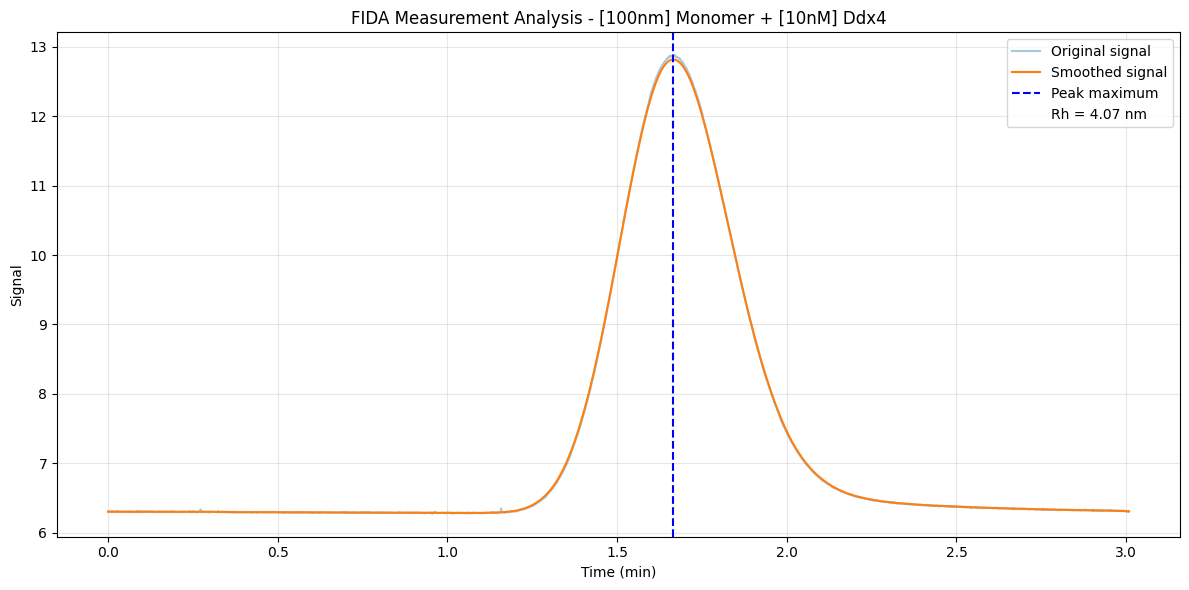

In [141]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit


# ==========================================
# 1. FIDA REFERENCE VALUES
# ==========================================

reference = {
    "Rh1": 3.48,
    "Area": 0.8861,
    "R2": 0.99951,
    "viscosity_Pa_s": 0.00089,
    "residence_time_min": 1.659988,
    "capillary_diameter_um": 75.0,
    "temperature_C": 25.0
}

print("REFERENCE VALUES")
print("================")

# Residence time is kept for calculations,
# but is not displayed here.
for parameter, value in reference.items():
    if parameter != "residence_time_min":
        print(f"{parameter}: {value}")


# ==========================================
# 2. LOAD CSV DATA
# ==========================================

# Replace this with your existing file path
file_name = r"C:\Users\1\Desktop\Bachelor\FIDA-DATA-CSV\Last experiment\100nM indicator + 10nM analyte-10-11-2026-17-52.csv"

data = pd.read_csv(
    file_name,
    sep=";",
    header=None,
    usecols=[0, 1],
    names=["x", "signal"],
    dtype=str
)

for col in ["x", "signal"]:
    data[col] = (
        data[col]
        .str.strip()
        .str.replace(",", ".", regex=False)
    )
    data[col] = pd.to_numeric(data[col], errors="raise")

x = data["x"].to_numpy(dtype=float)
signal_original = data["signal"].to_numpy(dtype=float)

# Sort data before analysis
order = np.argsort(x)
x = x[order]
signal_original = signal_original[order]

assert len(x) == len(signal_original)
assert np.isfinite(x).all()
assert np.isfinite(signal_original).all()

print("\nMEASUREMENT LOADED")
print("==================")
print(f"Measurements: {len(x)}")
print(f"First x: {x[0]:.6f}")
print(f"Last x: {x[-1]:.6f}")


# ==========================================
# 3. SMOOTHING
# ==========================================

window_length = 51
polyorder = 1

signal_smooth = savgol_filter(
    signal_original,
    window_length=window_length,
    polyorder=polyorder
)


# ==========================================
# 4. BASELINE CORRECTION
# ==========================================

baseline = np.linspace(
    signal_smooth[0],
    signal_smooth[-1],
    len(signal_smooth)
)

corrected = signal_smooth - baseline
weights = np.maximum(corrected, 0)


# ==========================================
# 5. AUTOMATIC PEAK FIT
# ==========================================

# Find peak maximum
peak_index = np.argmax(weights)

peak_x = x[peak_index]
peak_height = weights[peak_index]

# Gaussian model with offset
def gaussian(x, amplitude, center, sigma, offset):
    return (
        amplitude
        * np.exp(-0.5 * ((x - center) / sigma)**2)
        + offset
    )

# Fit around the peak
fit_mask = (
    (x >= peak_x - 0.5)
    & (x <= peak_x + 0.5)
)

x_fit = x[fit_mask]
y_fit = weights[fit_mask]

initial_guess = [
    peak_height,
    peak_x,
    0.15,
    0.0
]

parameters, covariance = curve_fit(
    gaussian,
    x_fit,
    y_fit,
    p0=initial_guess,
    bounds=(
        [0, x_fit.min(), 0.001, -np.inf],
        [np.inf, x_fit.max(), 1.0, np.inf]
    ),
    maxfev=20000
)

amplitude_fit, center_fit, sigma_fit, offset_fit = parameters

# Use fitted Gaussian width to define the interval.
# Three fitted standard deviations on either side.
left_time = center_fit - 3 * sigma_fit
right_time = center_fit + 3 * sigma_fit

# Restrict interval to available data
left_index = np.argmin(np.abs(x - left_time))
right_index = np.argmin(np.abs(x - right_time))

if right_index <= left_index:
    raise ValueError("Invalid fitted peak interval.")

x_peak = x[left_index:right_index + 1]
weights_peak = weights[left_index:right_index + 1]


# ==========================================
# 6. STANDARD WEIGHTED SIGMA
# ==========================================

area = np.trapezoid(weights_peak, x_peak)

if area <= 0:
    raise ValueError("Peak area must be positive.")

mu = (
    np.trapezoid(x_peak * weights_peak, x_peak)
    / area
)

variance = (
    np.trapezoid(
        (x_peak - mu)**2 * weights_peak,
        x_peak
    ) / area
)

sigma_min = np.sqrt(variance)
sigma_sec = sigma_min * 60

print("\nAUTOMATIC PEAK ANALYSIS")
print("=======================")
print(f"Peak maximum: {peak_x:.6f} min")
print(f"Fitted center: {center_fit:.6f} min")
print(f"Fitted Gaussian sigma: {sigma_fit * 60:.6f} sec")
print(f"Left boundary: {x_peak[0]:.6f} min")
print(f"Right boundary: {x_peak[-1]:.6f} min")
print(f"Peak area: {area:.6f}")
print(f"Standard sigma: {sigma_sec:.6f} sec")


# ==========================================
# 7. DIFFUSION COEFFICIENT AND Rh
# ==========================================

k_B = 1.380649e-23

temperature_K = reference["temperature_C"] + 273.15

viscosity = reference["viscosity_Pa_s"]

capillary_radius_m = (
    reference["capillary_diameter_um"] / 2
) * 1e-6

# Residence time is still used internally
residence_time_sec = (
    reference["residence_time_min"] * 60
)

# FIDA equation:
# D = (a² / (24 * sigma²)) * t_R

D = (
    capillary_radius_m**2
    * residence_time_sec
    / (24 * sigma_sec**2)
)

# Stokes-Einstein:
# Rh = kB*T / (6*pi*eta*D)

Rh_m = (
    k_B * temperature_K
    / (6 * np.pi * viscosity * D)
)

Rh_nm = Rh_m * 1e9


# ==========================================
# 8. HYDRODYNAMIC RADIUS DESCRIPTION
# ==========================================

Rh_difference = Rh_nm - reference["Rh1"]

Rh_percentage = (
    abs(Rh_difference) / reference["Rh1"]
) * 100

print("\nHYDRODYNAMIC RADIUS")
print("===================")
print(f"Diffusion coefficient: {D:.6e} m²/s")
print(f"Hydrodynamic radius Rh: {Rh_nm:.4f} nm")

print("\nRESULT DESCRIPTION")
print("==================")

print(
    f"The calculated hydrodynamic radius (Rh) "
    f"of the sample is {Rh_nm:.4f} nm. "
    f"The value was determined using "
    f"Gaussian-guided weighted moment analysis "
    f"(GGWMA), followed by the Stokes-Einstein equation."
)


# ==========================================
# 9. REFERENCE COMPARISON
# ==========================================

print("\nREFERENCE COMPARISON")
print("====================")
print(f"Calculated area: {area:.6f}")
print(f"Reference area: {reference['Area']:.6f}")
print(f"Calculated Rh: {Rh_nm:.4f} nm")
print(f"Reference Rh: {reference['Rh1']:.4f} nm")
print(f"Rh difference: {Rh_difference:.4f} nm")
print(f"Rh percentage difference: {Rh_percentage:.2f}%")


# ==========================================
# 10. PLOT FULL DATA
# ==========================================

plt.figure(figsize=(12, 6))

# Original signal - retained to show spikes
plt.plot(
    x,
    signal_original,
    alpha=0.4,
    label="Original signal"
)

# Smoothed signal
plt.plot(
    x,
    signal_smooth,
    linewidth=1.5,
    label=f"Smoothed signal"
)

# Blue dashed line at peak maximum
plt.axvline(
    peak_x,
    color="blue",
    linestyle="--",
    linewidth=1.5,
    label="Peak maximum"
)
plt.axvline(
    peak_x,
    color="blue",
    linestyle="",
    linewidth=1.5,
    label=f"Rh = {Rh_nm:.2f} nm"
)

plt.xlabel("Time (min)")
plt.ylabel("Signal")
plt.title("FIDA Measurement Analysis - [100nm] Monomer + [10nM] Ddx4")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
